# Census-Income (KDD): EDA and Preprocessing

**Conclusion: Compare 33 features after removing columns with year-specific recording and constant columns.** This notebook examines missingness, distributions, and associations in 215,574 adults from the two UCI files.

Environment: Colab or Kaggle. The first code cell downloads the data if it is not available.

In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd()
repo_root = cwd if (cwd / "src" / "data_loader.py").exists() else cwd.parent
assert (repo_root / "src" / "data_loader.py").exists(), "Run this notebook from the repository root or the notebooks/ directory."
data_path = repo_root / "data" / "processed" / "census_income_adults.csv"
if not data_path.exists():
    subprocess.run([sys.executable, "src/data_loader.py"], cwd=repo_root, check=True)

df = pd.read_csv(data_path, skipinitialspace=True)
assert df.shape == (215_574, 41)
assert "instance_weight" not in df.columns
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
display(df.head(3))

Extracting census-income.data ...
Extracting census-income.test ...
Combined rows: 299,285
Rows after age >= 18: 215,574
Saved: data/processed/census_income_adults.csv (215,574 rows, 41 columns)


Rows: 215,574 | Columns: 41


,age,class_of_worker,detailed_industry_recode,detailed_occupation_recode,education,wage_per_hour,enroll_in_edu_inst_last_wk,marital_stat,major_industry_code,major_occupation_code,...,country_of_birth_father,country_of_birth_mother,country_of_birth_self,citizenship,own_business_or_self_employed,fill_inc_questionnaire_for_veterans_admin,veterans_benefits,weeks_worked_in_year,year,income_class
0,73,Not in universe,0,0,High school graduate,0,Not in universe,Widowed,Not in universe or children,Not in universe,...,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,0,95,- 50000.
1,58,Self-employed-not incorporated,4,34,Some college but no degree,0,Not in universe,Divorced,Construction,Precision production craft & repair,...,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,52,94,- 50000.
2,18,Not in universe,0,0,10th grade,0,High school,Never married,Not in universe or children,Not in universe,...,Vietnam,Vietnam,Vietnam,Foreign born- Not a citizen of U S,0,Not in universe,2,0,95,- 50000.


## 1. Check missing values

**Rule: Treat only `?` as missing.** Keep `Not in universe` as a category indicating that the field does not apply.

In [2]:
# Strip whitespace from string columns and treat only ? as missing.
text_cols = df.select_dtypes(include=["object", "string"]).columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
df[text_cols] = df[text_cols].replace("?", pd.NA)

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_rate_pct": df.isna().mean().mul(100).round(2),
}).sort_values("missing_count", ascending=False)
display(missing[missing.missing_count > 0])

,missing_count,missing_rate_pct
migration_code_change_in_msa,107895,50.05
migration_code_change_in_reg,107895,50.05
migration_code_move_within_reg,107895,50.05
migration_prev_res_in_sunbelt,107895,50.05
country_of_birth_father,8361,3.88
country_of_birth_mother,7539,3.50
country_of_birth_self,4511,2.09
hispanic_origin,972,0.45
state_of_previous_residence,778,0.36


## Data quality: exact duplicates

In [3]:
duplicate_count = int(df.duplicated().sum())
duplicate_group_rows = int(df.duplicated(keep=False).sum())
predictor_columns = [col for col in df.columns if col != "income_class"]
conflicting_predictors = int((
    df.groupby(predictor_columns, dropna=False)["income_class"].nunique() > 1
).sum())
print(f"Additional exact duplicate rows: {duplicate_count:,} ({duplicate_count / len(df):.2%})")
print(f"Rows belonging to exact-duplicate groups: {duplicate_group_rows:,}")
print(f"Predictor patterns with conflicting income labels: {conflicting_predictors:,}")


Additional exact duplicate rows: 16,078 (7.46%)
Rows belonging to exact-duplicate groups: 22,089
Predictor patterns with conflicting income labels: 198


There are 16,078 duplicate lines (7.46%) that completely match other lines, excluding the first occurrence. However, there is no ID to identify individuals, so we cannot claim that these lines are duplicate records of the same person. Therefore, we did not eliminate the data for this reason. At the analysis phase, we will continuously pay attention to the possibility that lines with the same values appear in both the training and assessment data.

## 2. Proportion of `Not in universe` values (check constant columns)

In [4]:
not_in_universe = pd.DataFrame({
    "count": df.eq("Not in universe").sum(),
    "rate_pct": df.eq("Not in universe").mean().mul(100).round(2),
}).sort_values("count", ascending=False)
display(not_in_universe[not_in_universe["count"] > 0])

,count,rate_pct
family_members_under_18,215574,100.00
fill_inc_questionnaire_for_veterans_admin,212568,98.61
reason_for_unemployment,207175,96.10
enroll_in_edu_inst_last_wk,204565,94.89
region_of_previous_residence,198479,92.07
state_of_previous_residence,198479,92.07
member_of_labor_union,187686,87.06
migration_prev_res_in_sunbelt,90584,42.02
major_occupation_code,70991,32.93
class_of_worker,70700,32.80


## 3. Convert five numeric codes to categorical type

In [5]:
# These columns are nominal in .names but are read as integers from the CSV.
numeric_categorical = [
    "detailed_industry_recode", "detailed_occupation_recode",
    "own_business_or_self_employed", "veterans_benefits", "year",
]
print("Before:")
display(df[numeric_categorical].dtypes.to_frame("dtype"))
for col in numeric_categorical:
    df[col] = df[col].astype("string")
print("After:")
display(df[numeric_categorical].dtypes.to_frame("dtype"))

numeric_cols = [
    "age", "wage_per_hour", "capital_gains", "capital_losses",
    "dividends_from_stocks", "num_persons_worked_for_employer",
    "weeks_worked_in_year",
]
assert set(df.select_dtypes(include="number").columns) == set(numeric_cols)
display(df[numeric_cols].describe(percentiles=[.5, .95, .99]).T)

Before:


,dtype
detailed_industry_recode,int64
detailed_occupation_recode,int64
own_business_or_self_employed,int64
veterans_benefits,int64
year,int64


After:


,dtype
detailed_industry_recode,string
detailed_occupation_recode,string
own_business_or_self_employed,string
veterans_benefits,string
year,string


,count,mean,std,min,50%,95%,99%,max
age,215574.0,44.700080,17.671250,18.0,42.0,77.00,87.0,90.0
wage_per_hour,215574.0,75.164482,318.238453,0.0,0.0,688.35,1575.0,9999.0
capital_gains,215574.0,598.140778,5491.436919,0.0,0.0,991.00,14344.0,99999.0
capital_losses,215574.0,50.151925,313.866401,0.0,0.0,0.00,1974.0,4608.0
dividends_from_stocks,215574.0,271.303158,2278.620466,0.0,0.0,778.00,6000.0,99999.0
num_persons_worked_for_employer,215574.0,2.644939,2.399206,0.0,2.0,6.00,6.0,6.0
weeks_worked_in_year,215574.0,31.705679,23.468964,0.0,50.0,52.00,52.0,52.0


## 4. High income is 8.61% of the data (class imbalance)

In [6]:
class_counts = df["income_class"].value_counts(dropna=False)
display(pd.DataFrame({
    "count": class_counts,
    "rate_pct": class_counts.div(len(df)).mul(100).round(2),
}))

,count,rate_pct
income_class,,
- 50000.,197008,91.39
50000+.,18566,8.61


## 5. Histograms of seven numeric features by income class

**Purpose: Compare distributions across income classes.** `log1p` is used to display monetary features; it does not change the data.

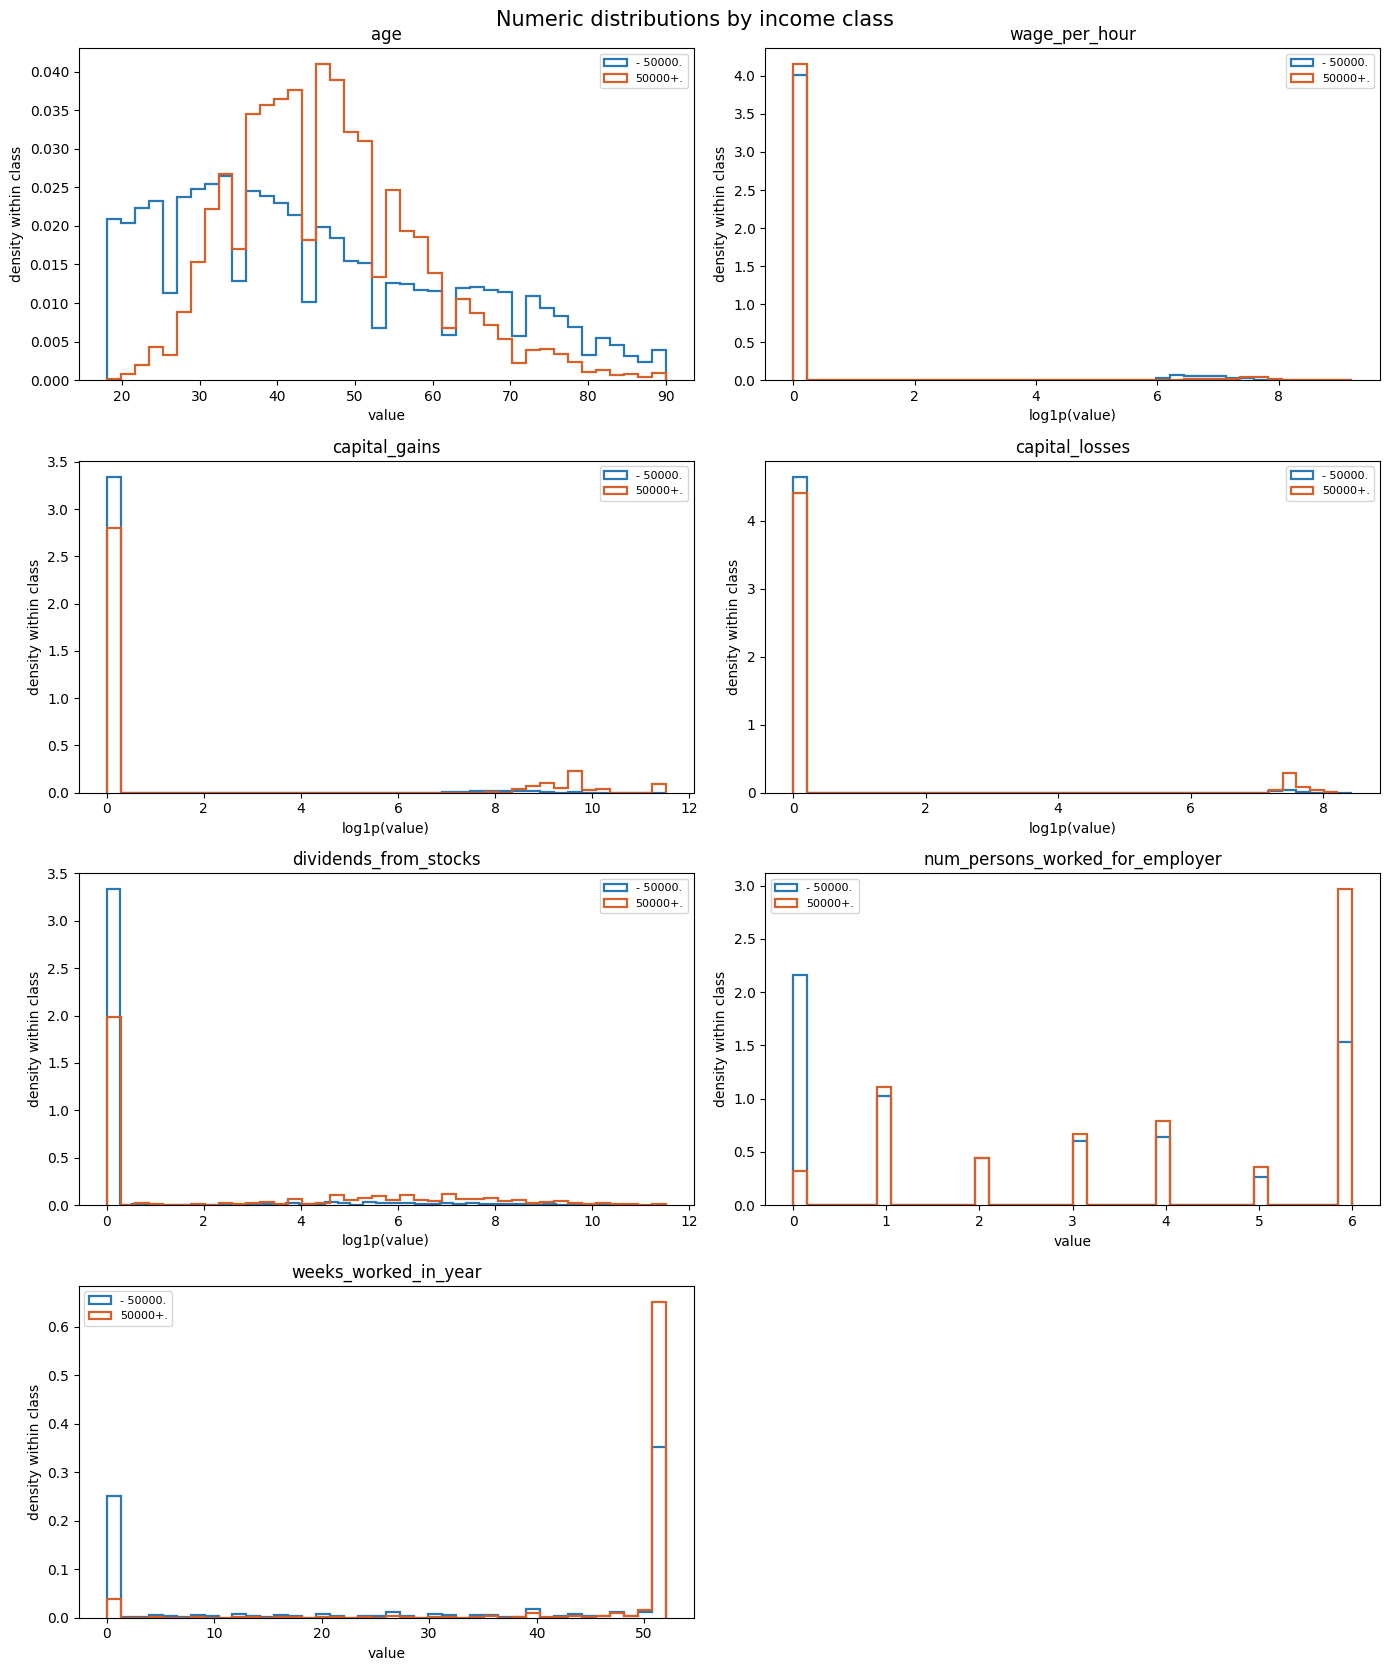

In [7]:
skewed_cols = {"wage_per_hour", "capital_gains", "capital_losses", "dividends_from_stocks"}
classes = sorted(df["income_class"].dropna().unique())
colors = ["#2878B5", "#D66027"]
fig, axes = plt.subplots(4, 2, figsize=(14, 17))
for ax, col in zip(axes.flat, numeric_cols):
    for label, color in zip(classes, colors):
        values = df.loc[df["income_class"] == label, col].dropna().to_numpy()
        if col in skewed_cols:
            values = np.log1p(values)
        ax.hist(values, bins=40, density=True, histtype="step", linewidth=1.6,
                color=color, label=label)
    ax.set_title(col)
    ax.set_xlabel("log1p(value)" if col in skewed_cols else "value")
    ax.set_ylabel("density within class")
    ax.legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Numeric distributions by income class", fontsize=15)
fig.tight_layout()
plt.show()

## 6. Box plots of seven numeric features by income class

**Purpose: Compare the center and spread of each distribution.** Outlier points are hidden. `log1p` is used to display monetary features.

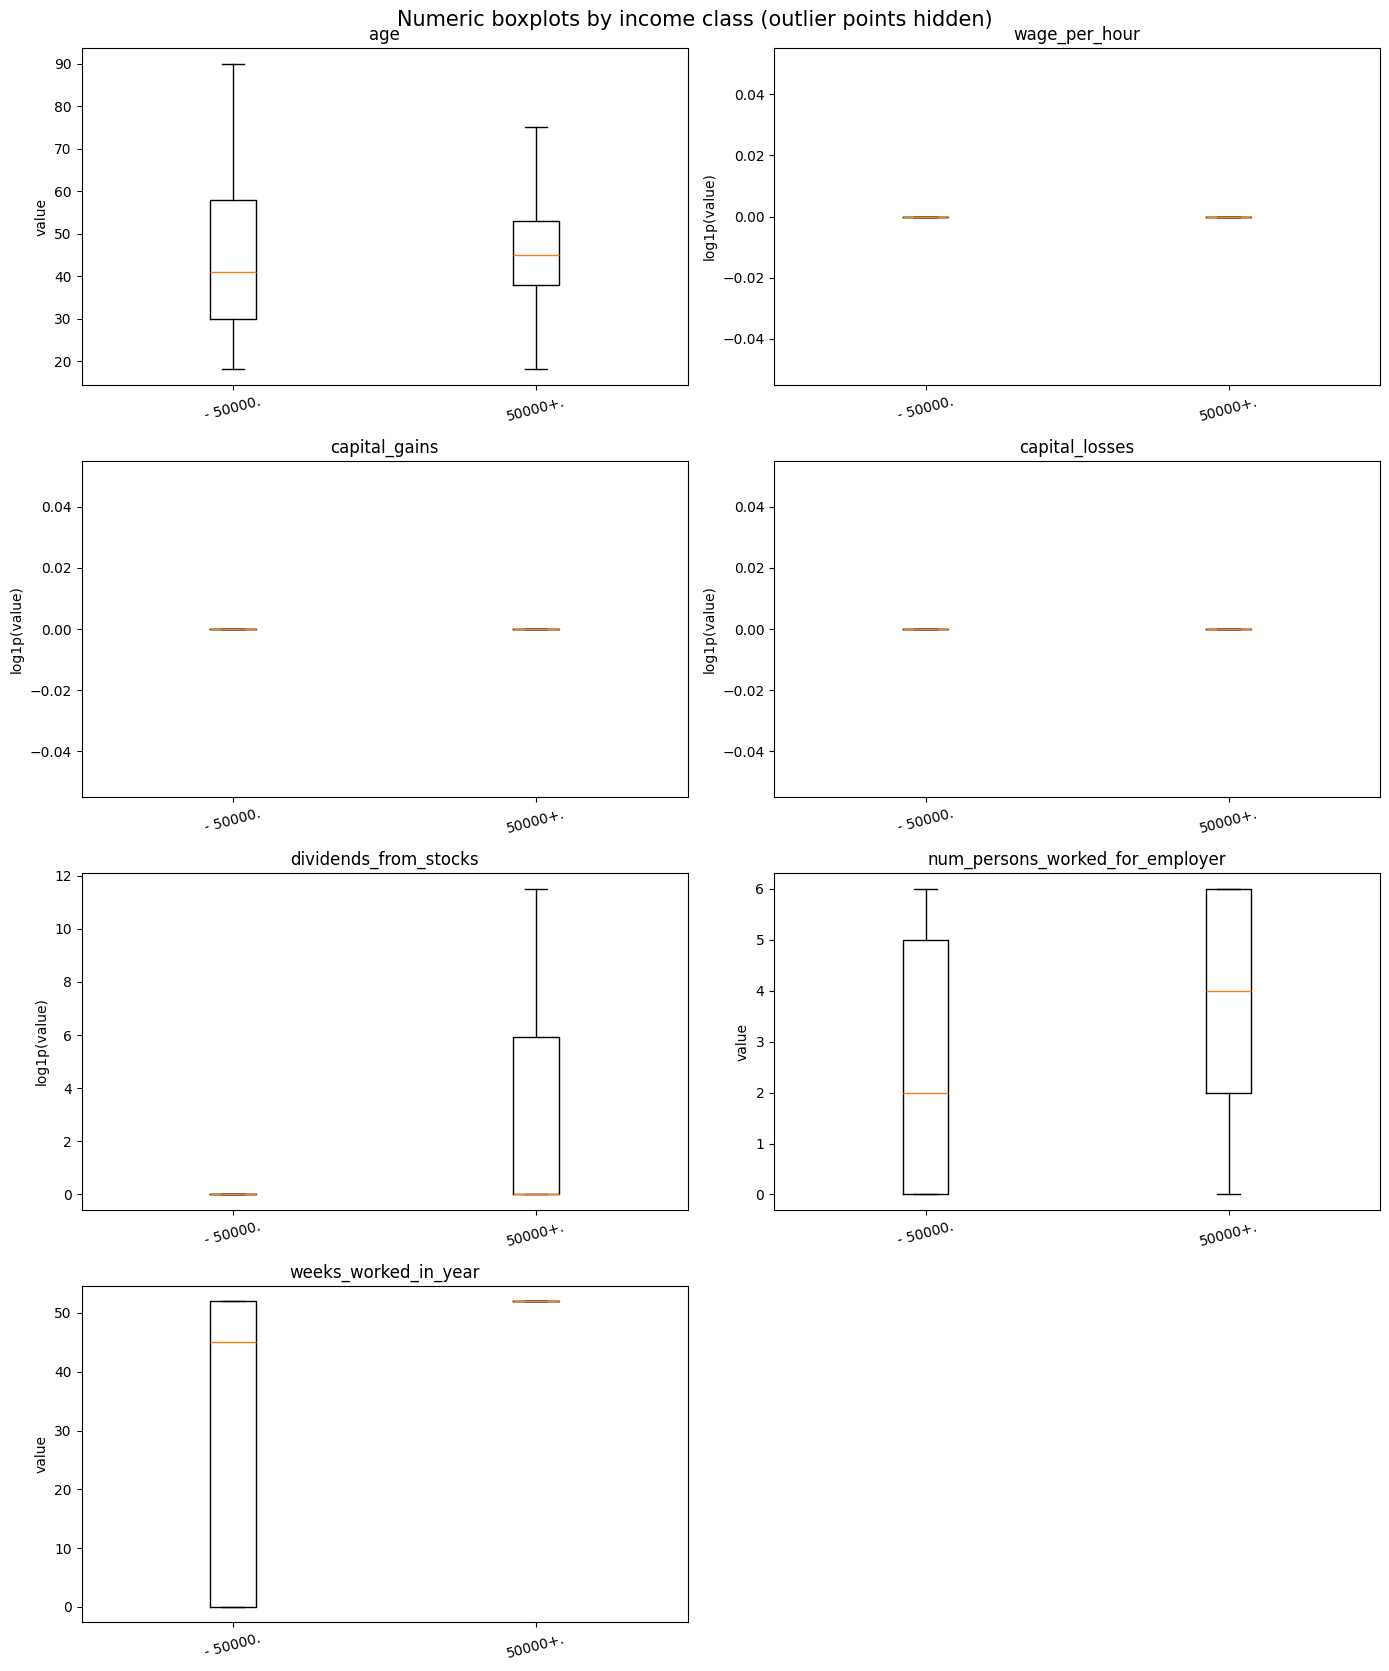

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(14, 17))
for ax, col in zip(axes.flat, numeric_cols):
    groups = []
    for label in classes:
        values = df.loc[df["income_class"] == label, col].dropna().to_numpy()
        groups.append(np.log1p(values) if col in skewed_cols else values)
    ax.boxplot(groups, tick_labels=classes, showfliers=False)
    ax.set_title(col)
    ax.set_ylabel("log1p(value)" if col in skewed_cols else "value")
    ax.tick_params(axis="x", labelrotation=15)
axes.flat[-1].axis("off")
fig.suptitle("Numeric boxplots by income class (outlier points hidden)", fontsize=15)
fig.tight_layout()
plt.show()

### Outlier summary

**Conclusion: Do not remove outliers from monetary columns wholesale.** Many values are zero, making the all-row IQR zero. Report outlier rates among nonzero values and high-income rates for zero versus nonzero values. It is unconfirmed whether 99,999 is a top-code.

In [9]:
def iqr_outlier_rate(values):
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr == 0:
        return np.nan  # The IQR rule cannot be applied when the IQR is zero.
    return ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).mean() * 100

is_high = df["income_class"].eq("50000+.")
outlier_rows = []
for col in numeric_cols:
    values = df[col]
    nonzero = values > 0
    outlier_rows.append({
        "feature": col,
        "zero_rate_pct": (~nonzero).mean() * 100,
        "IQR_outlier_rate_all_pct": iqr_outlier_rate(values),
        "IQR_outlier_rate_nonzero_pct": iqr_outlier_rate(values[nonzero]),
        "max": values.max(),
        "rows_at_max": int(values.eq(values.max()).sum()),
        "high_income_rate_if_nonzero_pct": is_high[nonzero].mean() * 100,
        "high_income_rate_if_zero_pct": is_high[~nonzero].mean() * 100,
    })
display(pd.DataFrame(outlier_rows).set_index("feature").round(2))

,zero_rate_pct,IQR_outlier_rate_all_pct,IQR_outlier_rate_nonzero_pct,max,rows_at_max,high_income_rate_if_nonzero_pct,high_income_rate_if_zero_pct
feature,,,,,,,
age,0.00,0.0,0.00,90,1098,8.61,NaN
wage_per_hour,92.44,NaN,3.73,9999,1,4.95,8.91
capital_gains,94.88,NaN,7.19,99999,578,32.60,7.32
capital_losses,97.36,NaN,8.71,4608,8,30.65,8.01
dividends_from_stocks,85.42,NaN,12.45,99999,31,25.38,5.75
num_persons_worked_for_employer,30.06,0.0,0.00,6,53424,11.71,1.40
weeks_worked_in_year,30.06,0.0,19.05,52,104663,11.71,1.40


## 7. Correlations among seven numeric features (two are employment-related)

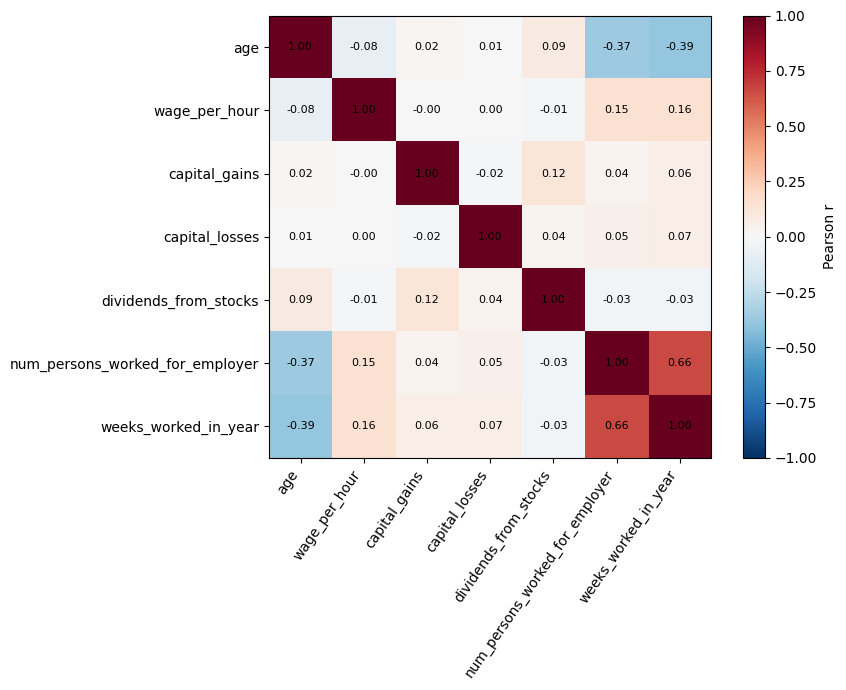

In [10]:
corr = df[numeric_cols].corr(method="pearson")
fig, ax = plt.subplots(figsize=(9, 7))
heat = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(numeric_cols)), labels=numeric_cols, rotation=55, ha="right")
ax.set_yticks(range(len(numeric_cols)), labels=numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(heat, ax=ax, label="Pearson r")
fig.tight_layout()
plt.show()

## 8. Associations among categorical features (Cramér's V)

**Conclusion: Do not drop a feature solely because it has a strong association with another.** Compute Cramér's V (0–1) between categorical features and the target. Count missing values as `Missing` and exclude constant columns.

Excluded constant columns: ['family_members_under_18']


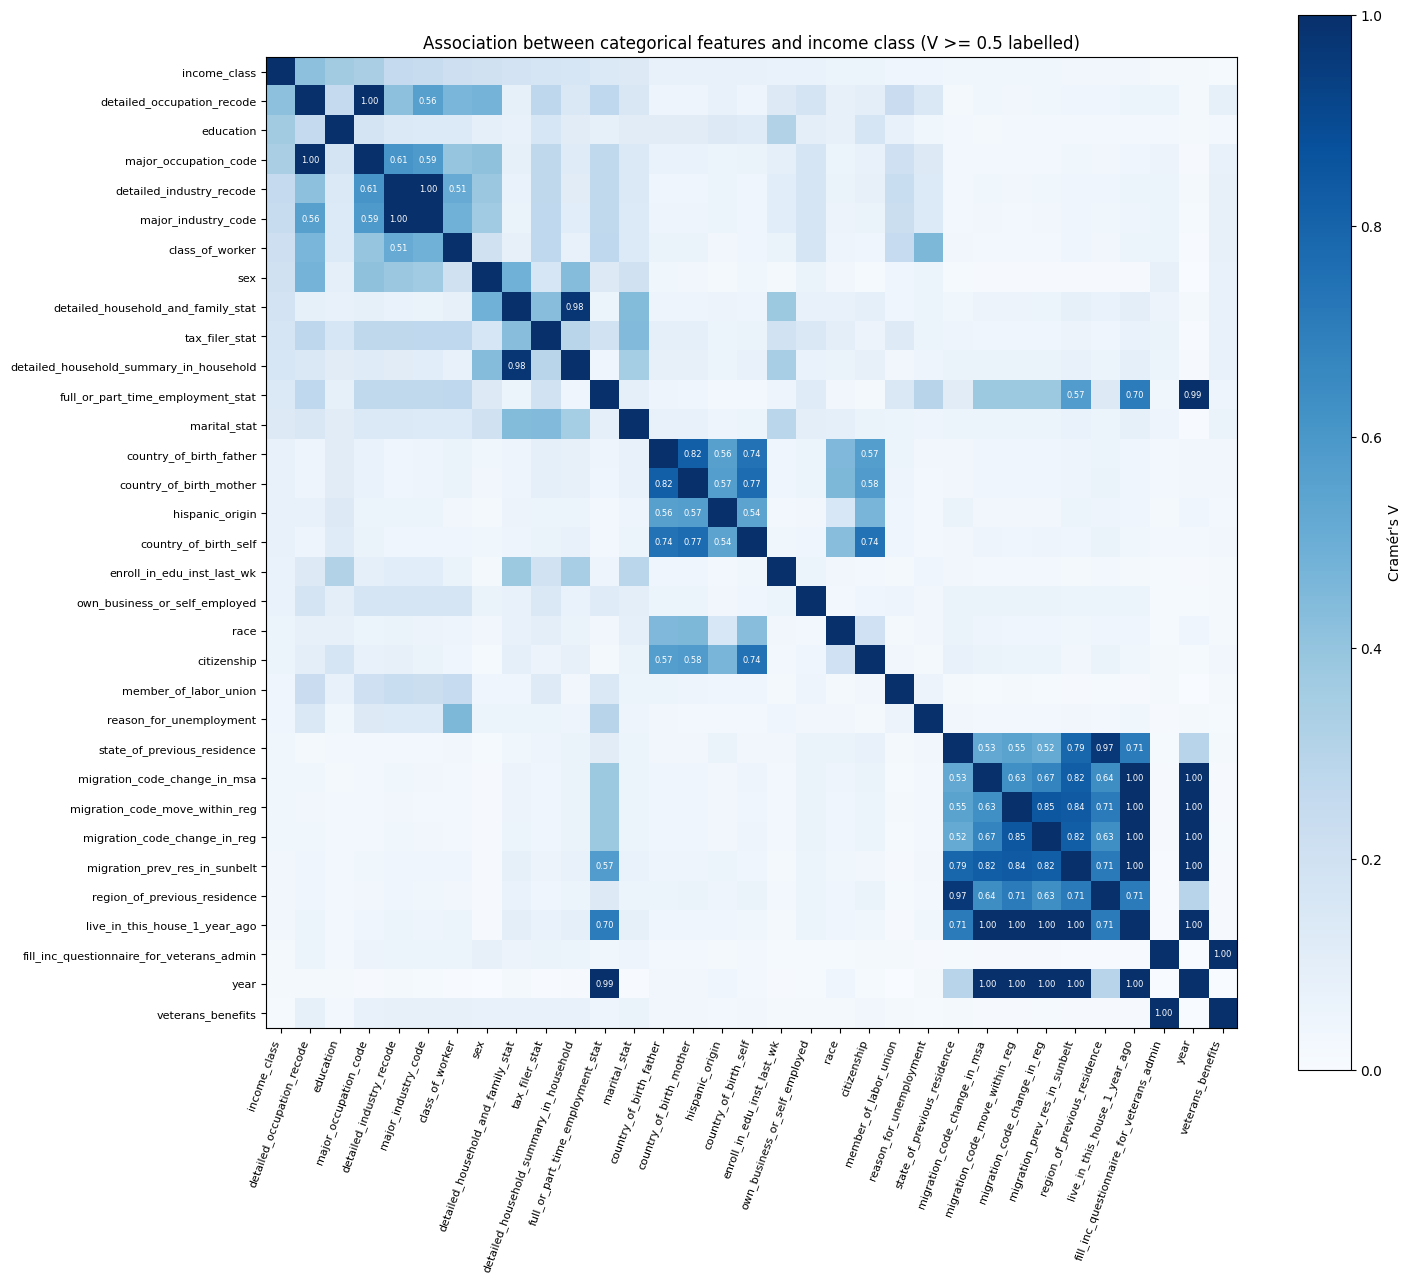

Most associated feature pairs:


cramers_v
migration_code_change_in_reg              year                                         1.000
fill_inc_questionnaire_for_veterans_admin veterans_benefits                            1.000
detailed_industry_recode                  major_industry_code                          1.000
live_in_this_house_1_year_ago             migration_code_change_in_reg                 1.000
                                          migration_prev_res_in_sunbelt                1.000
detailed_occupation_recode                major_occupation_code                        1.000
migration_code_move_within_reg            year                                         1.000
migration_prev_res_in_sunbelt             year                                         1.000
live_in_this_house_1_year_ago             migration_code_change_in_msa                 1.000
                                          migration_code_move_within_reg               1.000
                                          year                                         1.000
migration_code_change_in_msa              year                                         1.000
full_or_part_time_employment_stat         year                                         0.995
detailed_household_and_family_stat        detailed_household_summary_in_household      0.975
region_of_previous_residence              state_of_previous_residence                  0.967

Association with income_class:


,cramers_v
detailed_occupation_recode,0.415
education,0.360
major_occupation_code,0.337
detailed_industry_recode,0.253
major_industry_code,0.236
class_of_worker,0.215
sex,0.195
detailed_household_and_family_stat,0.182
tax_filer_stat,0.169
detailed_household_summary_in_household,0.163


In [11]:
from scipy.stats.contingency import association

categorical_cols = [c for c in df.columns if c not in numeric_cols and c != "income_class"]
constant_cols = [c for c in categorical_cols if df[c].nunique(dropna=False) == 1]
print("Excluded constant columns:", constant_cols)
cat_frame = df[[c for c in categorical_cols if c not in constant_cols] + ["income_class"]]
codes = {c: pd.factorize(cat_frame[c].fillna("Missing"))[0] for c in cat_frame.columns}

def cramers_v(a, b):
    n_a, n_b = a.max() + 1, b.max() + 1
    table = np.bincount(a * n_b + b, minlength=n_a * n_b).reshape(n_a, n_b)
    return association(table, method="cramer")

names = list(codes)
cramer = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for i, left in enumerate(names):
    for right in names[i + 1:]:
        cramer.loc[left, right] = cramer.loc[right, left] = cramers_v(codes[left], codes[right])

order = cramer["income_class"].sort_values(ascending=False).index
cramer = cramer.loc[order, order]
fig, ax = plt.subplots(figsize=(15, 13))
heat = ax.imshow(cramer, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(order)), labels=order, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(len(order)), labels=order, fontsize=8)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j and cramer.iloc[i, j] >= 0.5:
            ax.text(j, i, f"{cramer.iloc[i, j]:.2f}", ha="center", va="center",
                    fontsize=6, color="white")
fig.colorbar(heat, ax=ax, label="Cramér's V")
ax.set_title("Association between categorical features and income class (V >= 0.5 labelled)")
fig.tight_layout()
plt.show()

pairs = cramer.drop(index="income_class", columns="income_class").stack()
pairs = pairs[[a < b for a, b in pairs.index]].sort_values(ascending=False)
print("Most associated feature pairs:")
display(pairs.head(15).round(3).to_frame("cramers_v"))
print("Association with income_class:")
display(cramer["income_class"].drop("income_class").round(3).to_frame("cramers_v"))

## Notes and observations

**Conclusion: Use 33 features as the baseline and do not remove outliers wholesale.**

- **Excluded:** Four migration columns that are entirely missing in 1995; `family_members_under_18`, which is constant among adults; and `live_in_this_house_1_year_ago` and `full_or_part_time_employment_stat`, which are effectively constant in one year. Excluding the last two may discard signal from the year in which they vary.
- **Missingness:** Treat only `?` as missing. Keep `Not in universe` as a category. Missing rates for the three country-of-birth columns range from 2.09% to 3.88%.
- **Class balance:** There are 18,566 high-income records (8.61%). Use stratified splits and average precision (AP) as the primary metric. Choose class weighting with training cross-validation.
- **Numeric features:** The four monetary columns contain 85–97% zeros. `capital_gains` has 578 values of 99,999; it is unconfirmed whether this is a top-code. Compare raw and `log1p` values without removing outliers.
- **Associations:** The two employment-related features have a Pearson correlation of about 0.66. Detailed and broad occupation/industry features have Cramér's V = 1.00, but may not contain identical information, so keep them.
- **Next steps:** Fit imputation, scaling, one-hot encoding, and mutual information (MI) on training data only. Use PCA for visualization and do not use the final test set to make decisions.

# Preprocessing: Compare options

**Conclusion: Use 33 original features, raw monetary values, and no class weighting as the common baseline.** Training-only CV also compares 37 features with migration columns, `log1p`-transformed monetary values, and class weighting. No rows are removed.

These are preliminary results from 30,000 training rows. The held-out test set is not evaluated.

In [12]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

cwd = Path.cwd()
repo_root = cwd if (cwd / "src" / "preprocessing.py").exists() else cwd.parent
assert (repo_root / "src" / "preprocessing.py").exists(), "Run this notebook from the repository root or the notebooks/ directory."
sys.path.insert(0, str(repo_root / "src"))
from preprocessing import (
    MIGRATION_COLUMNS, MONEY_COLUMNS, NUMERIC_COLUMNS,
    build_preprocessor, prepare_xy, select_features,
)

data_path = repo_root / "data" / "processed" / "census_income_adults.csv"
if not data_path.exists():
    import subprocess
    subprocess.run([sys.executable, "src/data_loader.py"], cwd=repo_root, check=True)
df = pd.read_csv(data_path, skipinitialspace=True)
X, y = prepare_xy(df)
print(f"Rows: {len(X):,}, original features: {X.shape[1]}, positive rate: {y.mean():.2%}")

Rows: 215,574, original features: 40, positive rate: 8.61%


## 1. Stratified 80/20 split

**Decision: Hold out 20% for final evaluation.** Fit imputation, transformations, and mutual information (MI) on training data only.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "positive_count": [int(y_train.sum()), int(y_test.sum())],
    "positive_rate_pct": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["train", "test"])
display(split_summary)
assert len(X_train) + len(X_test) == 215_574

,rows,positive_count,positive_rate_pct
train,172459,14853,8.61
test,43115,3713,8.61


## 2. Preprocessing pipeline and one-hot feature count

**Pipeline: Median-impute and standardize numeric columns; impute categorical columns with `Missing` and one-hot encode them.** Allow unseen categories and fit on training data only.

In [14]:
feature_counts = []
for include_migration in (False, True):
    X_variant = select_features(X_train, include_migration)
    preprocessor = build_preprocessor(X_variant, log_money=False)
    transformed = preprocessor.fit_transform(X_variant)
    feature_counts.append({
        "migration": "keep" if include_migration else "drop",
        "original_features": X_variant.shape[1],
        "onehot_output_columns": transformed.shape[1],
        "sparse": bool(hasattr(transformed, "tocsr")),
    })
display(pd.DataFrame(feature_counts))

,migration,original_features,onehot_output_columns,sparse
0,drop,33,441,True
1,keep,37,471,True


## 3. Compare options on the same training sample and five folds

**Goal: Compare average precision (AP) on the same 30,000 rows and five folds.** Logistic regression is a preliminary reference model; its results need not generalize to other classifiers.

In [15]:
X_dev, _, y_dev, _ = train_test_split(
    X_train, y_train, train_size=30_000, stratify=y_train, random_state=42
)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
for include_migration in (False, True):
    X_variant = select_features(X_dev, include_migration)
    for log_money in (False, True):
        for class_weight in (None, "balanced"):
            model = Pipeline([
                ("preprocess", build_preprocessor(X_variant, log_money)),
                ("classifier", LogisticRegression(
                    solver="liblinear", max_iter=1000, class_weight=class_weight,
                    random_state=42,
                )),
            ])
            scores = cross_validate(
                model, X_variant, y_dev, cv=folds,
                scoring={"AP": "average_precision", "ROC_AUC": "roc_auc"},
                n_jobs=1, error_score="raise",
            )
            results.append({
                "migration": "keep" if include_migration else "drop",
                "money": "log1p" if log_money else "raw",
                "class_weight": class_weight or "none",
                "AP_mean": scores["test_AP"].mean(),
                "AP_sd": scores["test_AP"].std(),
                "ROC_AUC_mean": scores["test_ROC_AUC"].mean(),
                "fit_seconds_mean": scores["fit_time"].mean(),
            })
comparison = pd.DataFrame(results).sort_values("AP_mean", ascending=False)
display(comparison.round(4).reset_index(drop=True))
print(f"Random-ranking AP baseline: {y_dev.mean():.4f}")

,migration,money,class_weight,AP_mean,AP_sd,ROC_AUC_mean,fit_seconds_mean
0,drop,raw,none,0.6048,0.0076,0.9199,0.2609
1,keep,raw,none,0.6044,0.0070,0.9197,0.2641
2,keep,raw,balanced,0.5977,0.0090,0.9179,0.3261
3,drop,raw,balanced,0.5975,0.0095,0.9183,0.2795
4,drop,log1p,none,0.5927,0.0153,0.9181,0.2332
5,keep,log1p,none,0.5922,0.0149,0.9179,0.2603
6,drop,log1p,balanced,0.5834,0.0139,0.9159,0.2954
7,keep,log1p,balanced,0.5834,0.0133,0.9155,0.3305


Random-ranking AP baseline: 0.0861


## 4. Rank original features by mutual information

**Decision: Rank the 33 original features, not individual one-hot columns.** Mark categorical variables as discrete and use training rows only.

In [16]:
X_mi = select_features(X_dev, include_migration=False).copy()
cat_cols = [c for c in X_mi.columns if c not in NUMERIC_COLUMNS]
X_mi[NUMERIC_COLUMNS] = SimpleImputer(strategy="median").fit_transform(X_mi[NUMERIC_COLUMNS])
cat_imputed = SimpleImputer(strategy="constant", fill_value="Missing").fit_transform(X_mi[cat_cols])
X_mi[cat_cols] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(cat_imputed)
discrete_mask = [c in cat_cols for c in X_mi.columns]
mi_scores = mutual_info_classif(
    X_mi, y_dev, discrete_features=discrete_mask, random_state=42, n_neighbors=3
)
mi_ranking = pd.DataFrame({"feature": X_mi.columns, "MI_score": mi_scores})
mi_ranking = mi_ranking.sort_values("MI_score", ascending=False).reset_index(drop=True)
display(mi_ranking)

,feature,MI_score
0,detailed_occupation_recode,0.067893
1,major_occupation_code,0.052412
2,education,0.047368
3,detailed_industry_recode,0.033437
4,capital_gains,0.032297
5,dividends_from_stocks,0.031464
6,weeks_worked_in_year,0.031036
7,major_industry_code,0.030929
8,class_of_worker,0.023358
9,age,0.022934


We will choose the top 17 features from the 33 original features. There is a gap between the 17th (0.0104) and 18th (0.0053) features. To compare, we also keep all 33 features, and we will decide which feature set we are going to use at the analysis phase.

In [17]:
candidate_k = 17
full_33 = select_features(X_dev, include_migration=False).copy()
candidate_features = mi_ranking.head(candidate_k)["feature"].tolist()
candidate_17 = full_33.loc[:, candidate_features].copy()
assert full_33.shape[1] == 33 and candidate_17.shape[1] == candidate_k
print(f"Full feature set: {full_33.shape}")
print(f"Top-{candidate_k} candidate feature set: {candidate_17.shape}")
display(mi_ranking.head(candidate_k).assign(rank=range(1, candidate_k + 1))[["rank", "feature", "MI_score"]])

Full feature set: (30000, 33)
Top-17 candidate feature set: (30000, 17)


,rank,feature,MI_score
0,1,detailed_occupation_recode,0.067893
1,2,major_occupation_code,0.052412
2,3,education,0.047368
3,4,detailed_industry_recode,0.033437
4,5,capital_gains,0.032297
5,6,dividends_from_stocks,0.031464
6,7,weeks_worked_in_year,0.031036
7,8,major_industry_code,0.030929
8,9,class_of_worker,0.023358
9,10,age,0.022934


## 5. One-hot dimensionality and PCA

**Decision: Use PCA for exploration, not in the baseline pipeline.** On 30,000 training rows, inspect explained variance and plots by income class and survey year. Standardized numeric and 0/1 dummy columns do not have equal variance.

,explained_variance,components_needed,encoded_columns
0,0.80,31,440
1,0.90,63,440
2,0.95,99,440
3,0.99,191,440


Largest absolute loadings:


,PC1,PC2
0,other_numeric__weeks_worked_in_year,money__dividends_from_stocks
1,other_numeric__num_persons_worked_for_employer,money__capital_gains
2,other_numeric__age,other_numeric__age
3,categorical__major_industry_code_Not in univer...,money__capital_losses
4,categorical__major_occupation_code_Not in univ...,categorical__detailed_household_summary_in_hou...


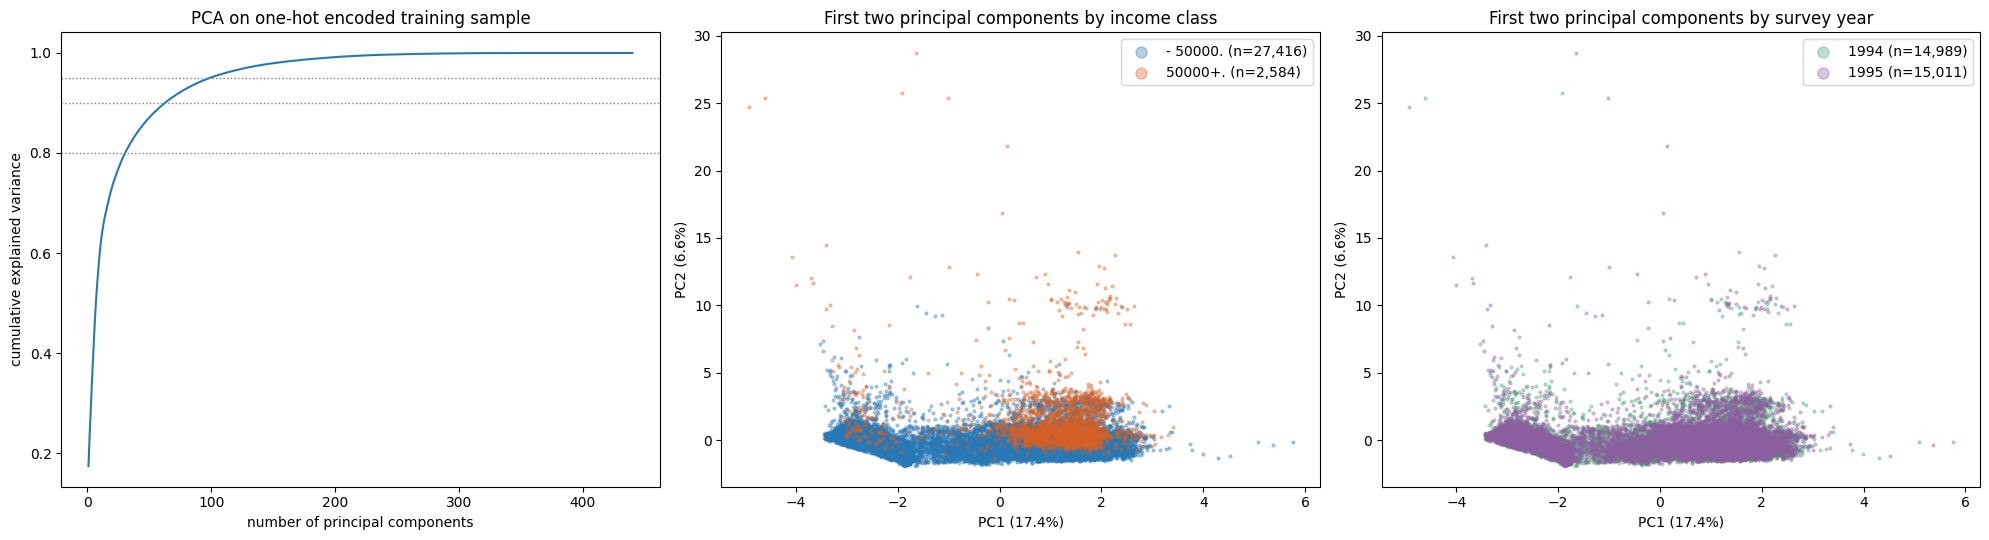

In [18]:
X_pca_source = select_features(X_dev, include_migration=False)
pca_preprocessor = build_preprocessor(X_pca_source, log_money=False)
X_encoded = pca_preprocessor.fit_transform(X_pca_source).toarray()
pca = PCA(random_state=42).fit(X_encoded)
cumulative = np.cumsum(pca.explained_variance_ratio_)
display(pd.DataFrame({
    "explained_variance": [0.80, 0.90, 0.95, 0.99],
    "components_needed": [int(np.searchsorted(cumulative, t) + 1) for t in (0.80, 0.90, 0.95, 0.99)],
    "encoded_columns": X_encoded.shape[1],
}))

feature_names = pca_preprocessor.get_feature_names_out()
loadings = pd.DataFrame({
    f"PC{i + 1}": pd.Series(pca.components_[i], index=feature_names)
    .abs().sort_values(ascending=False).head(5).index
    for i in range(2)
})
print("Largest absolute loadings:")
display(loadings)

components = pca.transform(X_encoded)[:, :2]
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].plot(np.arange(1, len(cumulative) + 1), cumulative, color="#2878B5")
for t in (0.80, 0.90, 0.95):
    axes[0].axhline(t, color="grey", linestyle=":", linewidth=1)
axes[0].set_xlabel("number of principal components")
axes[0].set_ylabel("cumulative explained variance")
axes[0].set_title("PCA on one-hot encoded training sample")
for label, name, color in ((0, "- 50000.", "#2878B5"), (1, "50000+.", "#D66027")):
    mask = y_dev.to_numpy() == label
    axes[1].scatter(components[mask, 0], components[mask, 1], s=4, alpha=0.35,
                    color=color, label=f"{name} (n={mask.sum():,})")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].set_title("First two principal components by income class")
axes[1].legend(markerscale=4)
year_values = X_pca_source["year"].to_numpy()
for year, color in (("94", "#4C9F70"), ("95", "#8E5EA2")):
    mask = year_values == year
    axes[2].scatter(components[mask, 0], components[mask, 1], s=4, alpha=0.35,
                    color=color, label=f"19{year} (n={mask.sum():,})")
axes[2].set_xlabel(axes[1].get_xlabel())
axes[2].set_ylabel(axes[1].get_ylabel())
axes[2].set_title("First two principal components by survey year")
axes[2].legend(markerscale=4)
fig.tight_layout()
plt.show()

## Decision notes

**Conclusion: Use 33 features, raw monetary values, and no class weighting as the common baseline.**

- **Columns:** Drop the four migration columns because all 1995 rows are missing them, not because of the negligible LR AP difference (0.0004). Also drop the constant column and two year-specific columns.
- **Monetary values:** LR AP is 0.6048 with raw values versus 0.5927 with `log1p`. Keep raw values as the baseline; assess other classifiers separately.
- **Class weights:** LR AP is 0.6048 without weighting versus 0.5975 with `balanced`. Use no weighting as the baseline, without assuming the result applies to other models.
- **Dimensionality:** One-hot encoding yields 441 columns on the full training set and 440 on the 30,000-row sample. PCA needs 63 components for 90% explained variance. The survey-year bands are no longer visible after removing the two year-specific columns. Do not include PCA in the baseline pipeline.
- **Feature selection:** We selected the top 17 features as a candidate set, but we also keep all 33 features to compare. We calculated MI only with the training dataset.

All results are preliminary and training-only. In later CV, fit preprocessing within each training fold.